In [1]:
import pydosert as PDRT
import numpy as np
import torch
import urllib.request
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import clear_output
import torch.nn.functional as F


#from pydosert.utils.plotting import overlay_mask_outline
#from pydosert.objectives.losses import penalty_upper


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import pydosert as PDRT

from pydosert.data import loaders
from pydosert.utils.utils import find_patient_paths

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

In [3]:
#SUPPOSEDLY THERE IS A BUG IN THE FETCH_PLAN_DATA FUNCTION, THIS BELOW PATCHES IT SO THAT A SOURCE TO SURFACE DISTANCE ISNT REQUIRED FOR EVERY CONTROL POINT. THE PARSER EXPECTS THIS BUT IT IS NOT WRITTEN INTO THE DICOM FILE FOR WHATEVER REASON.

import math
import pydicom
from pydosert.data.beam import Beam

def fetch_plan_data_tolerant(plan_path):
    """Drop-in for pydosert's fetch_plan_data: handles control points without
    SourceToSurfaceDistance and clips the MLC leaves to the ASYMX jaws."""
    ds = pydicom.dcmread(str(plan_path))
    fg = ds.FractionGroupSequence[0]
    n_frac = int(fg.NumberOfFractionsPlanned)
    metersets = {str(rb.ReferencedBeamNumber): float(rb.BeamMeterset)
                 for rb in fg.ReferencedBeamSequence if hasattr(rb, "BeamMeterset")}

    params = {}
    for beam in ds.BeamSequence:
        mu_tot = metersets.get(str(beam.BeamNumber))
        if mu_tot is None:
            continue
        gantry = coll = 0.0
        ssd = iso = None
        jaw_x = jaw_y = leaves = None
        old_mu, beams = 0.0, []
        for cp in beam.ControlPointSequence:   # later CPs only carry what changes
            if cp.get("GantryAngle") is not None:             gantry = float(cp.GantryAngle)
            if cp.get("BeamLimitingDeviceAngle") is not None: coll = float(cp.BeamLimitingDeviceAngle)
            if cp.get("SourceToSurfaceDistance") is not None: ssd = float(cp.SourceToSurfaceDistance)
            if cp.get("IsocenterPosition") is not None and iso is None:
                ip = cp.IsocenterPosition
                iso = (float(ip[2]), float(ip[1]), float(ip[0]))
            for s in cp.get("BeamLimitingDevicePositionSequence", []):
                p = np.array([float(v) for v in s.LeafJawPositions])
                if s.RTBeamLimitingDeviceType in ("ASYMX", "X"):   jaw_x = p
                elif s.RTBeamLimitingDeviceType in ("ASYMY", "Y"): jaw_y = p
                elif s.RTBeamLimitingDeviceType == "MLCX":
                    leaves = np.stack([p[: len(p) // 2], p[len(p) // 2:]], 1)

            mu_val = mu_tot * float(cp.CumulativeMetersetWeight)
            beams.append(Beam(
                gantry_angle=math.radians(gantry),
                collimator_angle=math.radians(coll),
                ssd=ssd,
                mu=torch.from_numpy(np.array(mu_val - old_mu)),
                leaf_positions=torch.from_numpy(np.clip(leaves, jaw_x[0], jaw_x[1])),
                jaw_positions=torch.from_numpy(jaw_y.copy()),
                field_size=(400, 400),
                sid=float(beam.SourceAxisDistance),
                iso_center=iso,
            ))
            old_mu = mu_val
        if beams:
            params[f"{ds.SOPInstanceUID}_{beam.BeamNumber}"] = (beams, n_frac)
    return params

# load_dicom calls the name imported into the loaders module, so patch it there
loaders.fetch_plan_data = fetch_plan_data_tolerant

In [4]:
# This makes the dose calculation not take forever
from pydosert.layers.BeamWiseConvolutionalLayer import BeamWiseConvolutionalLayer

def _fft_beamwise_conv(self, fluence_vol, kernels, chunk=256):
    """FFT equivalent of BeamWiseConvolutionalLayer.forward (grouped conv2d, padding='same')."""
    BG, D, H, W, _ = fluence_vol.shape
    kH, kW = kernels.shape[0], kernels.shape[1]
    x = fluence_vol.reshape(BG * D, H, W)
    k = kernels.permute(2, 3, 0, 1).reshape(BG * D, kH, kW).flip(-2, -1)  # conv2d is a correlation
    fh, fw = H + kH - 1, W + kW - 1
    ph, pw = (kH - 1) // 2, (kW - 1) // 2
    parts = []
    for s in range(0, BG * D, chunk):
        e = min(s + chunk, BG * D)
        y = torch.fft.irfft2(torch.fft.rfft2(x[s:e], s=(fh, fw)) * torch.fft.rfft2(k[s:e], s=(fh, fw)),
                             s=(fh, fw))
        parts.append(y[:, ph:ph + H, pw:pw + W])
    return torch.cat(parts).view(BG, D, H, W, 1)

_original_conv_forward = BeamWiseConvolutionalLayer.forward     # kept so you can undo it
BeamWiseConvolutionalLayer.forward = _fft_beamwise_conv

#To go back to the stock convolution:

#BeamWiseConvolutionalLayer.forward = _original_conv_forward

In [5]:
machine_config = PDRT.MachineConfig(preset = 'tb3_test')
patient_dir = 'CPPP-IMRT/'

ct_folder, rtplan_path, rtdose_path, rtstruct_path = find_patient_paths(patient_dir)

#torch.cuda.is_available()

patient, beam_sequences = loaders.load_dicom(
            ct_folder=ct_folder,
            dose_path=rtdose_path,
            plan_path=rtplan_path,
            struct_path=rtstruct_path,
            # new_spacing=(3, 3, 3),
            struct_names=["Avoid1", "Avoid2", "Body", "Center"],
            use_delivery=True,
            device = device #This is necessary if there is no GPU
            )
patient = patient.to('cpu').to(dtype) # This line is required for type matching in the dose engine
print(patient.structures.keys())

body = patient.structures["Body"]
BODY_RED = 1.0034 #Changing the electron density from air (0.0012) to water (1.0034)
density = torch.where(body, BODY_RED, 0.0012).to(dtype)

beam_sequence = beam_sequences[0] # This is the number of mus per beam

engine = PDRT.DoseEngine(
    machine_config=machine_config,
    dose_grid_spacing=patient.resolution,
    dose_grid_shape=patient.density_image.shape,
    kernel_size=75,
    beam_template=beam_sequence,
    device=device,
    dtype=dtype)

engine = PDRT.DoseEngine(
    machine_config=machine_config,
    dose_grid_spacing=tuple(patient.resolution),
    dose_grid_shape=tuple(density.shape), # here using the corrected density
    kernel_size=151,
    beam_template=beam_sequence,
    device=device,
    dtype=dtype,
    auto_calibrate=True)
#dose_fx = engine.compute_dose(beam_sequence.to_delivery(), density_image = density)

dict_keys(['Avoid1', 'Avoid2', 'Body', 'Center'])


c:\Users\mross\AppData\Local\Programs\Python\Python312\Lib\site-packages\pydosert\engine\dose_engine.py:340: UserWarning: In CPU autocast, but the target dtype is not supported. Disabling autocast.
CPU Autocast only supports dtypes of torch.bfloat16, torch.float16 currently.
  with torch.amp.autocast(self.device.type, dtype=self.dtype):


In [6]:
with torch.no_grad():
    dose_fx = engine.compute_dose(beam_sequence.to_delivery(), density_image = density, beam_chunk_size=10)
    #In the above, beam_chunk_size is crucial. This prevents the machine from crashing. 
    #Rather than looking at all 179 beam angles at once it breaks it into 10 chunks.

c:\Users\mross\AppData\Local\Programs\Python\Python312\Lib\site-packages\pydosert\engine\dose_engine.py:340: UserWarning: In CPU autocast, but the target dtype is not supported. Disabling autocast.
CPU Autocast only supports dtypes of torch.bfloat16, torch.float16 currently.
  with torch.amp.autocast(self.device.type, dtype=self.dtype):


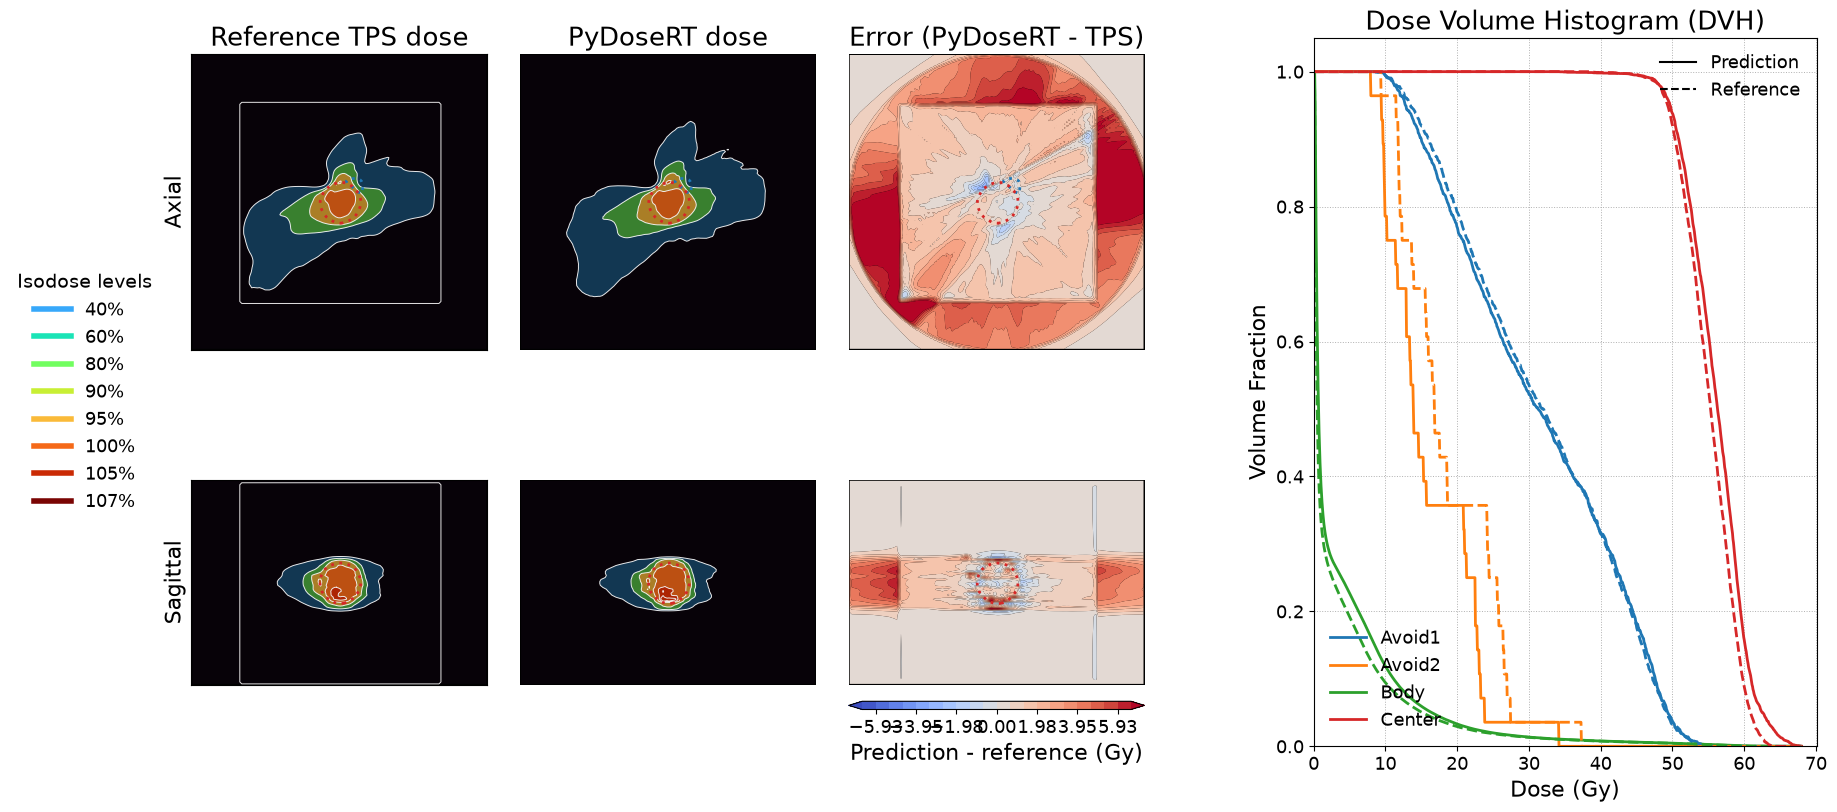

In [7]:
from pydosert.utils.plotting import plot_overview
plot_overview(patient, dose_pred=dose_fx, crop = False)

In [8]:
# This next bit is for writing out the patient in the same format as the water_patient.
#Export:

def save_patient(path, patient, density=None):
    arrays = {
        "ct": patient._ct_tensor.cpu().numpy(),             # HU (placeholder: all -1000)
        "resolution": np.array(patient.resolution, float),  # (z, y, x) mm
        "number_of_fractions": np.array(patient.number_of_fractions),
    }
    if density is not None:
        arrays["density"] = density.cpu().numpy()           # your Body = 1.0034 override
    if patient.dose is not None:
        arrays["dose"] = patient.dose.cpu().numpy()         # TPS reference, Gy per fraction
    for name, mask in patient.structures.items():
        arrays[f"struct_{name}"] = mask.cpu().numpy().astype(bool)
    np.savez_compressed(path, **arrays)

save_patient("CPPP_IMRT_patient.npz", patient, density)

#Load it back into a Patient:

def load_patient(path):
    d = np.load(path)
    structures = {k[len("struct_"):]: torch.from_numpy(d[k]) for k in d.files if k.startswith("struct_")}
    return PDRT.Patient(
        attenuation_tensor=torch.from_numpy(d["density"]) if "density" in d else None,
        ct_tensor=None if "density" in d else torch.from_numpy(d["ct"]),
        structures=structures,
        dose=torch.from_numpy(d["dose"]) if "dose" in d else None,
        resolution=tuple(d["resolution"]),
        number_of_fractions=int(d["number_of_fractions"]),
    )

patient2 = load_patient("CPPP_IMRT_patient.npz")
patient2.structures

{'Avoid1': tensor([[[False, False, False,  ..., False, False, False],
          [False, False, False,  ..., False, False, False],
          [False, False, False,  ..., False, False, False],
          ...,
          [False, False, False,  ..., False, False, False],
          [False, False, False,  ..., False, False, False],
          [False, False, False,  ..., False, False, False]],
 
         [[False, False, False,  ..., False, False, False],
          [False, False, False,  ..., False, False, False],
          [False, False, False,  ..., False, False, False],
          ...,
          [False, False, False,  ..., False, False, False],
          [False, False, False,  ..., False, False, False],
          [False, False, False,  ..., False, False, False]],
 
         [[False, False, False,  ..., False, False, False],
          [False, False, False,  ..., False, False, False],
          [False, False, False,  ..., False, False, False],
          ...,
          [False, False, False,  ..., F

In [9]:
#This function saves the label map in the same format as the water_patient.npz
def save_label_map(path, patient, body="Body", order=None):
    """Write patient.structures as a single label map, like water_patient.npz:
    0 = background, 1 = body, 2.. = the other structures (painted over the body).
    Where two non-body structures overlap, the later one in `order` wins."""
    if order is None:
        order = [n for n in patient.structures if n != body]
    names = [body] + list(order)

    shape = next(iter(patient.structures.values())).shape
    labels = np.zeros(shape, dtype=np.float64)
    for label, name in enumerate(names, start=1):
        labels[patient.structures[name].cpu().numpy().astype(bool)] = label

    np.savez_compressed(path, structures=labels)
    for label, name in enumerate(names, start=1):
        print(f"{label}: {name}  ({int((labels == label).sum())} voxels)")
    return {label: name for label, name in enumerate(names, start=1)}

label_names = save_label_map("CPPP_IMRT_labels.npz", patient, order=["Center", "Avoid1", "Avoid2"])

1: Body  (1003565 voxels)
2: Center  (4634 voxels)
3: Avoid1  (1276 voxels)
4: Avoid2  (28 voxels)


****************************************************************************************************************************************************************
FROM HERE ON IS A REPRODUCTION OF THE EXAMPLE OPTIMIZATION.IPYNB \
ABOVE WAS SORT OF A REPRODUCTION OF THE EXAMPLE DATA_LOADING.IPYNB
****************************************************************************************************************************************************************

In [10]:
from pydosert.utils.plotting import overlay_mask_outline
from pydosert.objectives.losses import upper_penalty

opt_patient = load_patient("CPPP_IMRT_patient.npz").to(dtype)   # float32 density, bool masks
opt_patient.structures.keys()

dict_keys(['Avoid1', 'Avoid2', 'Body', 'Center'])

In [11]:
S = opt_patient.structures
opt_patient.add_mask("External", S["Body"])                      # the full phantom
opt_patient.add_mask("Body", S["External"] & ~(S["Center"] | S["Avoid1"] | S["Avoid2"]),
                     overwrite=True)                             # body minus the other structures

colors = {
    "External": "orange",
    "Body": "purple",
    "Center": "yellow",
    "Avoid1": "green",
    "Avoid2": "blue",
}

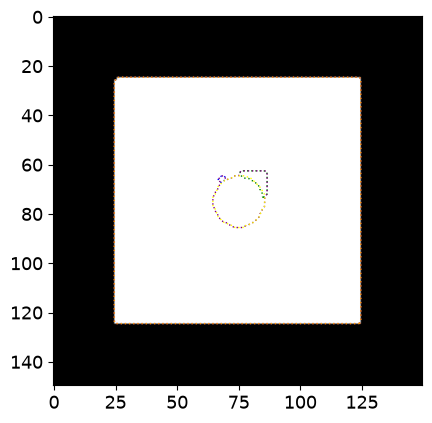

In [12]:
slice_idx = 50
plt.imshow(opt_patient.density_image.cpu().numpy()[slice_idx], cmap="gray")
for struct_name, mask in opt_patient.structures.items():
    overlay_mask_outline(mask.cpu().numpy()[slice_idx], color=colors[struct_name], sigma = 0.5) #sigma controls a gaussian blur mask on the exact voxels, 2.0 is default

In [13]:
#patient = patient.to(device).to(dtype)

#engine = PDRT.DoseEngine(
#    machine_config=machine_config,
#    dose_grid_spacing=patient.resolution,
#    dose_grid_shape=patient.density_image.shape,
#    beam_template=beam_sequence,
#    auto_calibrate=True,
#    kernel_size=151,
#    dtype=dtype,
#    device=device,
#)

#engine.train()


opt_patient = opt_patient.to(device).to(dtype)
S = opt_patient.structures

engine = PDRT.DoseEngine(
    machine_config=machine_config,
    dose_grid_spacing=tuple(opt_patient.resolution),
    dose_grid_shape=tuple(opt_patient.density_image.shape),
    beam_template=beam_sequence,
    auto_calibrate=True,
    kernel_size=151,
    beam_chunk_size=10,          # the fix for the crash(in memory)
    dtype=dtype,
    device=device,
)
engine.train()

ct_volume = patient.density_image.unsqueeze(0)

# plot_overview needs a CT for the background; make one from the density (plotting only)
plot_patient = PDRT.Patient(
    ct_tensor=(opt_patient.density_image - 1.0) * 1000.0,   # ~0 HU inside the phantom, ~-1000 HU outside
    structures=opt_patient.structures,
    dose=opt_patient.dose,
    resolution=opt_patient.resolution,
    number_of_fractions=opt_patient.number_of_fractions,
)

In [14]:
def plot_progress(epoch, raw_losses, dose_pred):
    clear_output(wait = True)
    print(f"Epoch {epoch}: {[str(np.round(loss.item(), 3))for loss in raw_losses]}")
    plot_overview(plot_patient, dose_pred = dose_pred)


In [15]:
from dataclasses import replace

# Neutral start: raw zeros -> leaf pairs centred on 0 and half open (~±25 mm),
# jaws at about ±37 mm, softplus(0) ≈ 0.69 MU per segment
raw_seq = replace(
    beam_sequence,
    leaf_positions=torch.zeros_like(beam_sequence.leaf_positions, dtype=dtype).requires_grad_(True),
    jaw_positions=torch.zeros_like(beam_sequence.jaw_positions, dtype=dtype).requires_grad_(True),
    mus=torch.zeros_like(beam_sequence.mus, dtype=dtype).requires_grad_(True),
)

#raw_seq keeps the arc geometry (gantry angles, isocenter, number of segments) from beam_sequence and only resets the parameters the optimizer will change.

In [16]:
#prescribed_dose = 5000
#avoid1_limit = 2500
#avoid2_limit = 1000

#patience = 0
#epoch = 0
#num_epochs = 5

n_fx = opt_patient.number_of_fractions      # 25
prescribed_dose = 50.0                      # Gy, full course
avoid1_limit = 25.0
avoid2_limit = 10.0
num_epochs = 3

optimizer = torch.optim.LBFGS(
    raw_seq.parameters(),
    lr=1.0,                    # standard for L-BFGS; line search handles step sizing
    max_iter=5,                # inner iterations per .step() call
    max_eval=7,                # ~1.25 * max_iter
    tolerance_grad=1e-7,
    tolerance_change=1e-9,
    history_size=10,            # curvature pairs to keep; 10–20 is the sweet spot
    line_search_fn="strong_wolfe",  # critical — without this it's much less robust
)
last_raw_losses = None
last_dose_pred = None

def make_ordered_pairs(x: torch.Tensor, min_opening: float = 0.0, max_opening: float = 100.0) -> torch.Tensor:
    """
    x: [..., 2]
    Interprets:
      x[..., 0] = center
      x[..., 1] = raw width parameter

    Returns:
      ordered pairs [..., 2] where:
        left  = center - width/2
        right = center + width/2
      and width >= min_opening

    Uses sigmoid — it saturates less aggressively in absolute terms than
    tanh (at raw x=3: sigmoid output is 95% of max, tanh is 99.5%), so the
    gradient stays usable across the full output range.
    """
    center = (max_opening * torch.sigmoid(x[..., 0])) - max_opening / 2.0
    width = min_opening + ((max_opening - min_opening) * torch.sigmoid(x[..., 1]))

    left = center - 0.5 * width
    right = center + 0.5 * width

    return torch.stack([left, right], dim=-1)

def closure():
    global last_raw_losses, last_dose_pred
    optimizer.zero_grad(set_to_none=True)

    seq = replace(
        raw_seq,
        leaf_positions=make_ordered_pairs(raw_seq.leaf_positions, min_opening=1.0),
        jaw_positions=make_ordered_pairs(raw_seq.jaw_positions, min_opening=1.0, max_opening=150.0),
        mus=F.softplus(raw_seq.mus),
    )
    dose_fx = engine.compute_dose(seq, density_image=opt_patient.density_image)[0]   # Gy per fraction
    dose = torch.where(S["External"], dose_fx, 0.0) * n_fx                           # Gy, full course

    raw_losses = [
        100.0 * torch.mean((dose[S["Center"]] - prescribed_dose) ** 2),
        upper_penalty(dose[S["Avoid1"]], avoid1_limit),
        upper_penalty(dose[S["Avoid2"]], avoid2_limit),
        10.0 * torch.mean(dose[S["External"]] ** 2),
    ]
    loss = torch.stack(raw_losses).sum()
    loss.backward()

    last_raw_losses = [l.detach() for l in raw_losses]
    last_dose_pred = dose_fx.detach()
    return loss              

# Once the loss is going down, the max_iter/max_eval and num_epochs can be raised

Epoch 2: ['265.017', '203.133', '556.286', '1039.281']


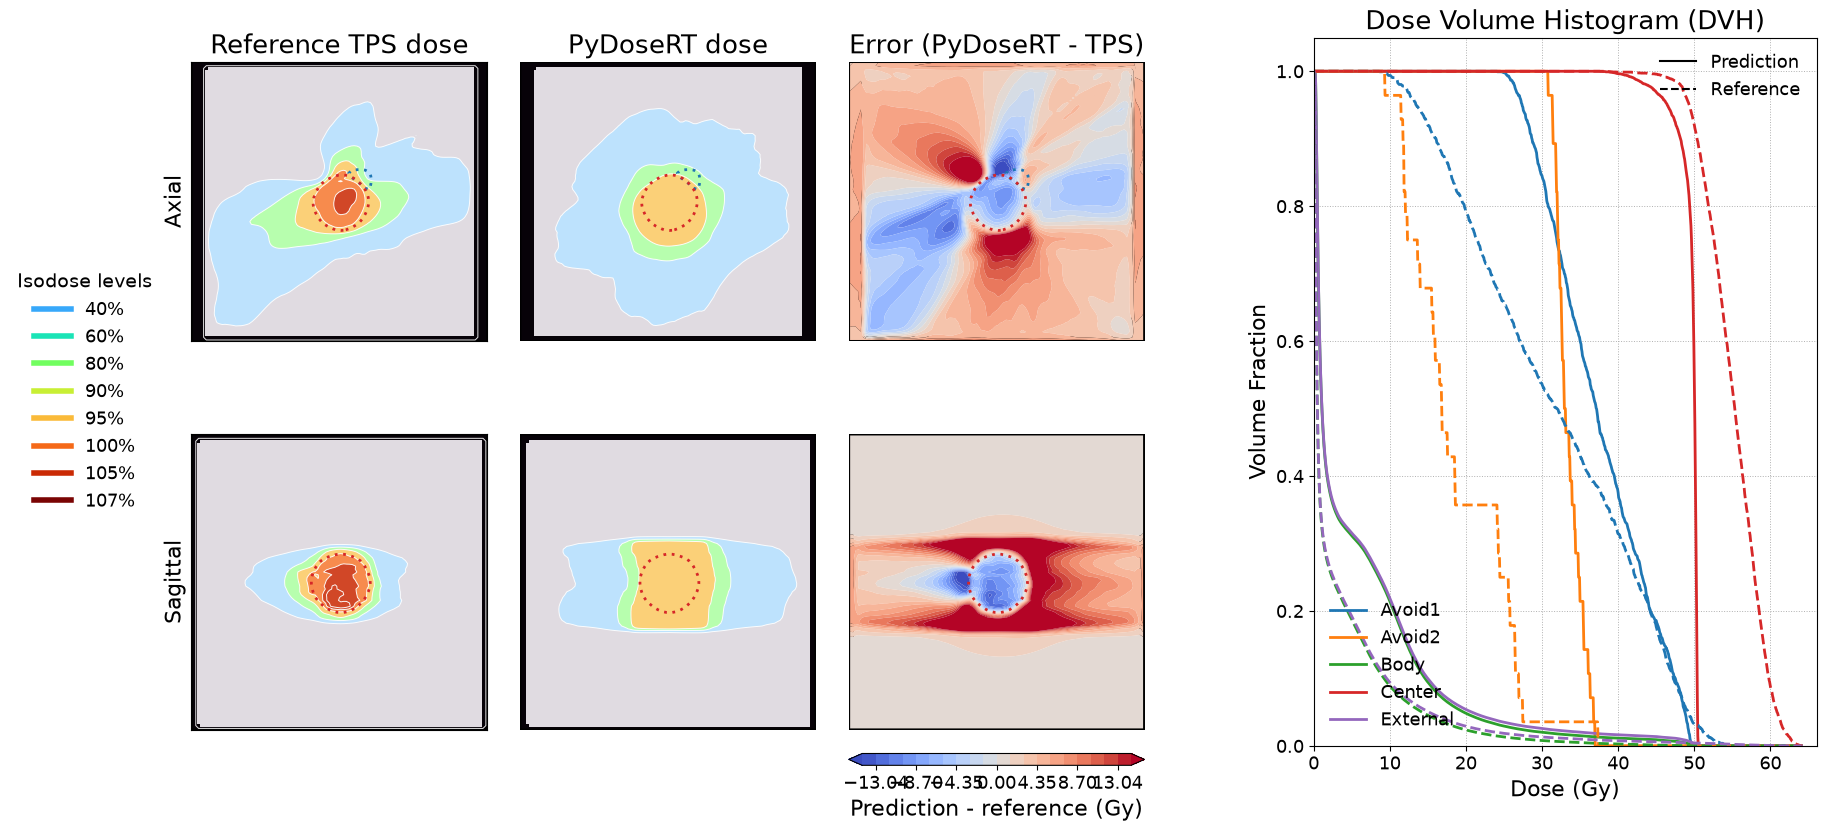

In [17]:
for i in range(num_epochs):
    x = optimizer.step(closure)
    plot_progress(i, last_raw_losses, last_dose_pred)

Metric                      Goal   Optimized   TPS ref
Center mean (Gy)          ≈ 50.0       49.53     55.18
Center D98 (Gy)           ≥ 47.5       43.73     48.17
Center D2 (Gy)            ≤ 53.5       50.45     62.00
Center V95% (%)             ≥ 95       92.45     98.59
HI (D2-D98)/D50              → 0        0.13      0.25
Paddick CI                   → 1        0.45      0.88
Avoid1 max (Gy)           ≤ 25.0       49.78     55.47
Avoid1 D2 (Gy)            ≤ 25.0       49.29     51.20
Avoid1 mean (Gy)                       37.55     31.79
Avoid1 V25Gy (%)               0       99.76     65.52
Avoid2 max (Gy)           ≤ 10.0       36.96     37.30
Avoid2 mean (Gy)                       33.52     18.89
Avoid2 V10Gy (%)               0      100.00     96.43
External mean (Gy)           low        5.45      3.18
External max (Gy)                      50.49     64.13


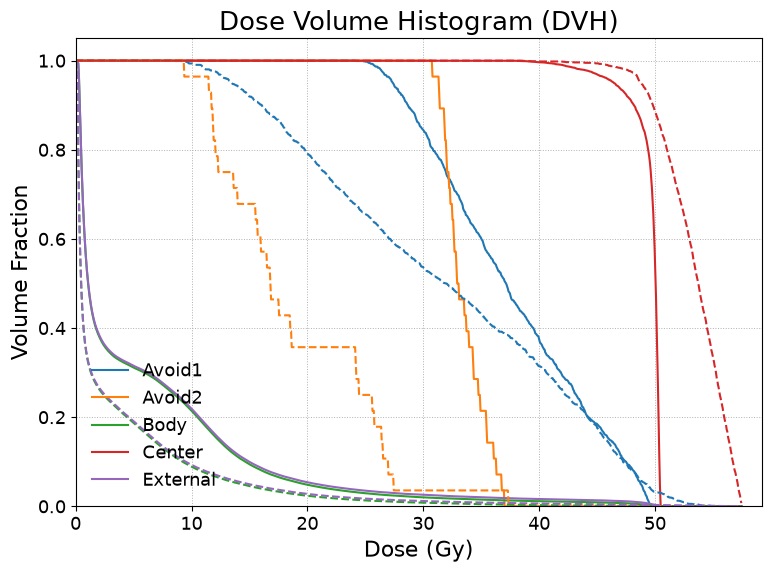

In [18]:
from pydosert.utils.plotting import plot_dvh

# --- 1. Final dose from the accepted parameters ---
with torch.no_grad():
    final_seq = replace(
        raw_seq,
        leaf_positions=make_ordered_pairs(raw_seq.leaf_positions, min_opening=1.0),
        jaw_positions=make_ordered_pairs(raw_seq.jaw_positions, min_opening=1.0, max_opening=150.0),
        mus=F.softplus(raw_seq.mus),
    )
    final_dose_fx = engine.compute_dose(final_seq, density_image=opt_patient.density_image)[0]
    final_dose_fx = torch.where(S["External"], final_dose_fx, 0.0)   # Gy / fraction

final_dose = (final_dose_fx * n_fx).cpu().numpy()                   # Gy, full course
ref_dose = (opt_patient.dose * n_fx).cpu().numpy() if opt_patient.dose is not None else None
masks = {k: v.cpu().numpy().astype(bool) for k, v in S.items()}

# --- 2. DVH metrics ---
def D(d, pct):   # dose received by the hottest `pct`% of the volume
    return np.percentile(d, 100 - pct)

def V(d, dose):  # % of the volume receiving >= dose
    return 100.0 * np.mean(d >= dose)

def metrics(dose):
    c, a1, a2, ext = (dose[masks[k]] for k in ("Center", "Avoid1", "Avoid2", "External"))
    rx = prescribed_dose
    v_rx_ext = np.sum(ext >= rx)                     # prescription isodose volume (voxels)
    return {
        "Center mean (Gy)":   (c.mean(),            f"≈ {rx}"),
        "Center D98 (Gy)":    (D(c, 98),            f"≥ {0.95*rx:.1f}"),
        "Center D2 (Gy)":     (D(c, 2),             f"≤ {1.07*rx:.1f}"),
        "Center V95% (%)":    (V(c, 0.95*rx),       "≥ 95"),
        "HI (D2-D98)/D50":    ((D(c,2)-D(c,98))/D(c,50), "→ 0"),
        "Paddick CI":         (np.sum(c >= rx)**2 / (c.size * v_rx_ext) if v_rx_ext else 0, "→ 1"),
        "Avoid1 max (Gy)":    (a1.max(),            f"≤ {avoid1_limit}"),
        "Avoid1 D2 (Gy)":     (D(a1, 2),            f"≤ {avoid1_limit}"),
        "Avoid1 mean (Gy)":   (a1.mean(),           ""),
        f"Avoid1 V{avoid1_limit:g}Gy (%)": (V(a1, avoid1_limit), "0"),
        "Avoid2 max (Gy)":    (a2.max(),            f"≤ {avoid2_limit}"),
        "Avoid2 mean (Gy)":   (a2.mean(),           ""),
        f"Avoid2 V{avoid2_limit:g}Gy (%)": (V(a2, avoid2_limit), "0"),
        "External mean (Gy)": (ext.mean(),          "low"),
        "External max (Gy)":  (ext.max(),           ""),
    }

opt_m = metrics(final_dose)
ref_m = metrics(ref_dose) if ref_dose is not None else None

print(f"{'Metric':<22}{'Goal':>10}{'Optimized':>12}{'TPS ref':>10}")
for k, (val, goal) in opt_m.items():
    ref = f"{ref_m[k][0]:10.2f}" if ref_m else ""
    print(f"{k:<22}{goal:>10}{val:12.2f}{ref}")

# --- 3. DVH: optimized (solid) vs TPS (dashed) ---
plot_dvh(plot_patient, dose_pred=final_dose_fx, dose_vmax=1.15 * prescribed_dose)

In [ ]:
# Scrollable slice viewer: structure outlines (solid) + isodose lines (dashed)
# Uses final_dose / ref_dose / masks (full-course Gy) from the evaluation cell above
import ipywidgets as widgets
from matplotlib.lines import Line2D

doses = {"Optimized": final_dose}
if ref_dose is not None:
    doses["TPS reference"] = ref_dose

density_np = opt_patient.density_image.cpu().numpy()
struct_np = {k: masks[k] for k in ("External", "Center", "Avoid1", "Avoid2")}
res = [float(r) for r in opt_patient.resolution]                # (z, y, x) mm
center_vox = np.argwhere(struct_np["Center"]).mean(0).round().astype(int)

iso_pct = [107, 100, 95, 80, 50, 20]                            # % of prescription
iso_colors = ["magenta", "red", "orange", "yellow", "lime", "cyan"]
views = {"Axial": 0, "Coronal": 1, "Sagittal": 2}

def draw(view, idx, source, wash):
    axis = views[view]
    sl = lambda vol: np.take(vol, idx, axis=axis)
    row_res, col_res = [res[i] for i in range(3) if i != axis]
    aspect = row_res / col_res
    d = sl(doses[source])

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(sl(density_np), cmap="gray", vmin=0, vmax=1.5, aspect=aspect)
    if wash:
        ax.imshow(np.ma.masked_less(d, 0.2 * prescribed_dose), cmap="jet", alpha=0.35,
                  vmin=0, vmax=1.1 * prescribed_dose, aspect=aspect)

    handles = []
    for name, m in struct_np.items():
        if sl(m).any():
            ax.contour(sl(m), levels=[0.5], colors=[colors[name]], linewidths=1.5)
        handles.append(Line2D([], [], color=colors[name], lw=1.5, label=name))
    for pct, c in zip(iso_pct, iso_colors):
        level = pct / 100 * prescribed_dose
        if d.min() < level < d.max():
            ax.contour(d, levels=[level], colors=[c], linewidths=1.2, linestyles="--")
        handles.append(Line2D([], [], color=c, lw=1.2, ls="--", label=f"{pct}% ({level:.1f} Gy)"))

    ax.set_title(f"{source} | {view} slice {idx} | slice max {d.max():.1f} Gy")
    ax.axis("off")
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
    plt.show()

view_w = widgets.ToggleButtons(options=list(views), value="Axial")
source_w = widgets.Dropdown(options=list(doses), description="Dose")
wash_w = widgets.Checkbox(value=False, description="Colour wash")
slice_w = widgets.IntSlider(value=int(center_vox[0]), min=0, max=density_np.shape[0] - 1,
                            description="Slice", layout=widgets.Layout(width="600px"))

def _on_view(change):                                           # new view -> new slice range, start at the target
    axis = views[change["new"]]
    slice_w.max = density_np.shape[axis] - 1
    slice_w.value = int(center_vox[axis])
view_w.observe(_on_view, names="value")

out = widgets.interactive_output(draw, {"view": view_w, "idx": slice_w, "source": source_w, "wash": wash_w})
display(widgets.VBox([widgets.HBox([view_w, source_w, wash_w]), slice_w, out]))

*********************************************************************************************************************************************************************************
BELOW HERE IS SIMPLY MESSING AROUND GARBAGE
********************************************************************************************************************************************************************************

In [21]:
from pydosert.utils.plotting import overlay_mask_outline
from pydosert.objectives.losses import upper_penalty

#raw_data = patient2.structures
local_path = Path('CPPP_IMRT_labels.npz')
raw_data = np.load(local_path)["structures"]
label_names

{1: 'Body', 2: 'Center', 3: 'Avoid1', 4: 'Avoid2'}

In [47]:
ct_image = torch.from_numpy(np.where(raw_data != 0.0, 0.0, -1000.0))
external = torch.from_numpy(raw_data > 0.0)
body = torch.from_numpy(raw_data == 1.0)
center = torch.from_numpy(raw_data == 2.0)
Avoid1 = torch.from_numpy(raw_data == 3.0)
Avoid2 = torch.from_numpy(raw_data == 4.0)

patient = PDRT.Patient(ct_tensor = ct_image, resolution = (2.0,2.0,2.0))
patient.add_mask("External", external)
patient.add_mask("Body", body)
patient.add_mask("Center", center)
patient.add_mask("Avoid1", Avoid1)
patient.add_mask("Avoid2", Avoid2)

colors = {
    "External":"orange",
    "Body": "purple",
    "Center":"yellow",
    "Avoid1": "green",
    "Avoid2": "blue"
}

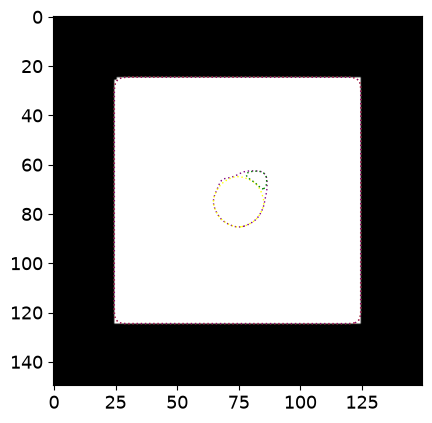

In [48]:
slice_idx = 50
plt.imshow(patient.density_image.cpu().detach().numpy()[slice_idx, :, :], cmap="gray")
for struct_name in patient.structures.keys():
    overlay_mask_outline(
        patient.structures[struct_name].cpu().detach().numpy()[slice_idx, :, :],
        color=colors[struct_name],
    )

In [83]:
engine.calibrate(110,beam_sequence)

The argument `original_beam_template` is now deprecated and will not be used for calibration


c:\Users\mross\AppData\Local\Programs\Python\Python312\Lib\site-packages\pydosert\engine\dose_engine.py:265: UserWarning: In CPU autocast, but the target dtype is not supported. Disabling autocast.
CPU Autocast only supports dtypes of torch.bfloat16, torch.float16 currently.
  parts.append(dose.new_zeros((dose.shape[0], d1 - d0, *dose.shape[2:])))


Calibration failed. Adjusting calibration factor to: 0.0030384010440590815


In [ ]:
patient = patient.to(engine.dtype).to(engine.device)
beam_sequence = beam_sequence.to(engine.device).to(engine.dtype)
with torch.no_grad():
    dose = engine.compute_dose(beam_sequence, density_image=patient.density_image).detach().cpu().numpy()

c:\Users\mross\AppData\Local\Programs\Python\Python312\Lib\site-packages\pydosert\engine\dose_engine.py:265: UserWarning: In CPU autocast, but the target dtype is not supported. Disabling autocast.
CPU Autocast only supports dtypes of torch.bfloat16, torch.float16 currently.
  parts.append(dose.new_zeros((dose.shape[0], d1 - d0, *dose.shape[2:])))


In [80]:
beam_sequences

[BeamSequence(mus=tensor([ 1.3677,  2.7354,  2.7354,  2.6054,  2.4555,  2.4356,  2.4356,  2.4356,
          2.6326,  3.0584,  3.1611,  3.2481,  3.2481,  2.8237,  2.8237,  3.2804,
          3.8109,  4.4273,  5.1202,  6.0197,  7.4129,  8.3782,  7.6405,  6.2217,
          5.2524,  4.7240,  4.5944,  4.5944,  4.4850,  4.4359,  4.4359,  4.5129,
          4.4239,  4.4223,  4.6668,  4.6992,  4.3861,  4.0608,  3.9283,  3.6154,
          3.2845,  2.9254,  2.5278,  2.2425,  2.2425,  2.5278,  2.9366,  3.4115,
          3.5041,  3.1088,  2.7120,  2.3704,  2.0404,  1.8878,  1.8878,  1.8878,
          1.8878,  1.8878,  1.8373,  1.8324,  1.1513,  0.9930,  2.0676,  2.8614,
          3.3978,  3.9259,  4.1181,  4.3136,  4.3056,  3.7551,  3.4051,  3.1457,
          2.7695,  2.3609,  2.0881,  1.9341,  1.7205,  1.5895,  1.5895,  1.5895,
          1.6608,  1.7322,  1.7322,  1.7322,  1.5954,  1.4585,  1.4585,  1.4585,
          1.5471,  1.6357,  1.6357,  1.6357,  1.8734,  2.1111,  2.1111,  2.1111,
          2

In [65]:
from pydicom import dcmread
import dicom
import pydicom
from pydicom.data import get_testdata_file
ex = get_testdata_file("rtstruct.dcm")
#ds = dicom.read_file("CPPP-IMRT/RS.CPPP.PHANTOM.dcm", force = True)
ds = dcmread(ex, force=True)
ds.dtype

AttributeError: 'FileDataset' object has no attribute 'dtype'

In [ ]:
# Example: 3D volume from multiple DICOM slices
dicom_files = sorted(Path("path/to/dicom/files").glob("*.dcm"))
volumes = [pydicom.dcmread(f).pixel_array for f in dicom_files]
np.savez("volume.npz", data=np.stack(volumes, axis=0))

ModuleNotFoundError: No module named 'dicom_numpy'

In [57]:
local_path = Path('water_patient.npz')

In [58]:
test = np.load(local_path)
test['structures'][3][45]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0.])

In [62]:
test['structures']

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.

In [39]:
np.argwhere(test['structures']>0)

array([[ 21, 118,  95],
       [ 21, 118,  96],
       [ 21, 118,  97],
       ...,
       [105, 153, 162],
       [105, 153, 163],
       [105, 153, 164]], shape=(1490298, 3))

In [41]:
test['structures'].shape

(106, 194, 194)

In [42]:
test['structures'][21,118,95]

np.float64(2.0)